In [ ]:
!pip install transformers

In [ ]:
from transformers import BertModel, BertTokenizer, get_linear_schedule_with_warmup
from torch.optim import AdamW
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from textwrap import wrap
from sklearn.metrics import f1_score

In [ ]:
#INICIALIZARON
RANDOM_SEED = 42
MAX_LEN = 150
BATCH_SIZE = 32
NCLASSES = 2

In [ ]:
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [ ]:
df = pd.read_csv("dataset_ready_nlp.csv")

In [ ]:
df.head(5)

,text,labels,idioma
0,rt that bitch ugly rt daughter.,1.0,ingles
1,"definitely a crowdpleaser , but then , so was ...",0.0,ingles
2,hard to resist his pleas to spare wildlife and...,0.0,ingles
3,shit he prolly is other than that everybody el...,1.0,ingles
4,8220 128514 marcus bitch ass aint loyal at all...,1.0,ingles


In [ ]:
df['text'].duplicated().any()

np.False_

In [ ]:
df['text'].value_counts()

,count
text,
the gorgeous piano,1
rt that bitch ugly rt daughter.,1
"definitely a crowdpleaser , but then , so was the roman colosseum .",1
hard to resist his pleas to spare wildlife and respect their environs,1
shit he prolly is other than that everybody else trash,1
...,...
cuz ur a bird bitch,1
"liotta put on 30 pounds for the role , and has completely transformed himself from his smooth , goodfellas image .",1
highly watchable stuff .,1


In [ ]:
df['text'].duplicated().sum()

np.int64(0)

In [ ]:
#REAJUSTE DE DATA
# Los datos ya están binarizados en dataset_ready_nlp.csv (0.0 y 1.0)
df['labels'] = df['labels'].astype(int)
df.head()

,text,labels,idioma
0,rt that bitch ugly rt daughter.,1,ingles
1,"definitely a crowdpleaser , but then , so was ...",0,ingles
2,hard to resist his pleas to spare wildlife and...,0,ingles
3,shit he prolly is other than that everybody el...,1,ingles
4,8220 128514 marcus bitch ass aint loyal at all...,1,ingles


In [ ]:
df['labels'].isna().sum()

np.int64(0)

In [ ]:
df['labels'] = df['labels'].fillna('unknown')

In [ ]:
print(df['labels'].unique())
print(df['labels'].apply(type).value_counts())

[1 0]
labels
<class 'int'>    56062
Name: count, dtype: int64


In [ ]:
df = df[df['labels'] != 'unknown']

In [ ]:
print(df)

                                                    text  labels   idioma
0                        rt that bitch ugly rt daughter.       1   ingles
1      definitely a crowdpleaser , but then , so was ...       0   ingles
2      hard to resist his pleas to spare wildlife and...       0   ingles
3      shit he prolly is other than that everybody el...       1   ingles
4      8220 128514 marcus bitch ass aint loyal at all...       1   ingles
...                                                  ...     ...      ...
56057                        ray rice bitch!!!!!!!!!!!!!       1   ingles
56058  rt my dick is called abusive cat owner because...       1   ingles
56059                     learn how to type ya hillbilly       1   ingles
56060  un excelente ejemplo de cuando se usa un térmi...       0  español
56061                                 the gorgeous piano       0   ingles

[56062 rows x 3 columns]


In [ ]:
#TOKENIZACION
PRE_TRAINED_MODEL_NAME = 'bert-base-multilingual-cased'
tokenizer = BertTokenizer.from_pretrained(PRE_TRAINED_MODEL_NAME)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
#EJEMPLO TOKENIZACION
simple_tex = "bro eres un pendejo 😴"
tokens = tokenizer.tokenize(simple_tex)
tokens_ids = tokenizer.convert_tokens_to_ids(tokens)
print('frase', simple_tex)
print('tokens', tokens)
print('tokens numericos', tokens_ids)

frase bro eres un pendejo 😴
tokens ['bro', 'ere', '##s', 'un', 'pen', '##dej', '##o', '[UNK]']
tokens numericos [93742, 14378, 10107, 10119, 66558, 90062, 10133, 100]


In [ ]:
#CODIFICACION PARA INTRUDUCIR BERTH
encoding = tokenizer(
    simple_tex,
    max_length = 15,
    truncation = True,
    add_special_tokens = True,
    return_token_type_ids = False,
    padding = 'max_length',
    return_attention_mask = True,
    return_tensors = 'pt'
)

In [ ]:
encoding.keys()

KeysView({'input_ids': tensor([[  101, 93742, 14378, 10107, 10119, 66558, 90062, 10133,   100,   102,
             0,     0,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])})

In [ ]:
print(tokenizer.convert_ids_to_tokens(encoding['input_ids'][0]))
print(encoding['input_ids'][0])
print(encoding['attention_mask'][0])

['[CLS]', 'bro', 'ere', '##s', 'un', 'pen', '##dej', '##o', '[UNK]', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
tensor([  101, 93742, 14378, 10107, 10119, 66558, 90062, 10133,   100,   102,
            0,     0,     0,     0,     0])
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0])


In [ ]:
class IMBDataset(Dataset):
    def __init__(self, Text, Label, tokenizer, max_len):
        self.Text = list(Text)
        self.Label = list(Label)
        self.tokenizer = tokenizer
        self.max_len = max_len

        # Optimización: Pre-tokenizar todo el texto de una vez
        print("Pre-tokenizando datos...")
        self.encodings = tokenizer(
            self.Text,
            max_length=self.max_len,
            truncation=True,
            add_special_tokens=True,
            padding='max_length',
            return_attention_mask=True,
            return_tensors='pt'
        )
        self.input_ids = self.encodings['input_ids']
        self.attention_mask = self.encodings['attention_mask']
        print("Tokenización completada!")

    def __len__(self):
        return len(self.Text)

    def __getitem__(self, item):
        # Se obtiene el dato pre-calculado directo de RAM, O(1)
        return {
            'Text': self.Text[item],
            'input_ids': self.input_ids[item],
            'attention_mask': self.attention_mask[item],
            'labels': torch.tensor(self.Label[item], dtype=torch.long)
        }

In [ ]:
#DATA LOADER
def data_loader(df, tokenizer, max_len, batch_size):
    dataset = IMBDataset(
        Text=df.text.to_numpy(),
        Label=df.labels.to_numpy(),
        tokenizer=tokenizer,
        max_len=max_len
    )
    return DataLoader(
        dataset,
        batch_size=batch_size,
        num_workers=2,
        pin_memory=True
    )

In [ ]:
#seperacion de data para las pruebas
df_train, df_temp = train_test_split(
    df,
    test_size=0.3,
    random_state=RANDOM_SEED,
    stratify=df['labels']
)

df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=RANDOM_SEED,
    stratify=df_temp['labels']
)

train_data_loader = data_loader(df_train, tokenizer, MAX_LEN, BATCH_SIZE)
val_data_loader   = data_loader(df_val, tokenizer, MAX_LEN, BATCH_SIZE)
test_data_loader  = data_loader(df_test, tokenizer, MAX_LEN, BATCH_SIZE)

Pre-tokenizando datos...
Tokenización completada!
Pre-tokenizando datos...
Tokenización completada!
Pre-tokenizando datos...
Tokenización completada!


In [ ]:
print("\n=== DIAGNÓSTICO DE DATOS ===")
print(f"Total de registros: {len(df)}")
print(f"\nDistribución de clases:")
print(df['labels'].value_counts())

# Probar un batch
sample_batch = next(iter(train_data_loader))
print(f"\nForma de input_ids: {sample_batch['input_ids'].shape}")
print(f"Forma de attention_mask: {sample_batch['attention_mask'].shape}")
print(f"Forma de labels: {sample_batch['labels'].shape}")
print(f"Labels en el batch: {sample_batch['labels']}")
print(f"Ejemplo de texto: {sample_batch['Text'][0]}")


=== DIAGNÓSTICO DE DATOS ===
Total de registros: 56062

Distribución de clases:
labels
1    28031
0    28031
Name: count, dtype: int64

Forma de input_ids: torch.Size([32, 150])
Forma de attention_mask: torch.Size([32, 150])
Forma de labels: torch.Size([32])
Labels en el batch: tensor([0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1,
        0, 1, 1, 1, 1, 1, 1, 0])
Ejemplo de texto: reasonably entertaining sequel


In [ ]:
class BERTModerador(nn.Module):

  def __init__(self,n_classes):
    super(BERTModerador,self).__init__()
    self.bert = BertModel.from_pretrained(PRE_TRAINED_MODEL_NAME)
    self.dropout = nn.Dropout(p=0.3) #Dropout apaga aleatoriamente el 30% de las neuronas durante el entrenamiento
    self.linear = nn.Linear(
        self.bert.config.hidden_size, #anclamos las capas de salida de bert con las clases que queremos predecir
        n_classes
    )

  def forward(self, input_ids, attention_mask): #Este método define cómo fluye la información en el modelo.
    outputs = self.bert(
        input_ids = input_ids,
        attention_mask = attention_mask
    )
    pooled_output = outputs.pooler_output #Es la representación del token [CLS]
    x = self.dropout(pooled_output) #Aplica dropout al vector [CLS]
    logits = self.linear(x) #Los logits son los valores crudos que salen del modelo antes de aplicar una función de activación como softmax o sigmoid.
    return logits


In [ ]:
model = BERTModerador(NCLASSES)
model = model.to(device)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
print(model)

BERTModerador(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(119547, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_af

In [ ]:
#ENTRENAMIENTO
EPOCHS = 7

from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
import torch.nn as nn

# Optimizador
optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)


total_steps = len(train_data_loader) * EPOCHS

# Scheduler (control del learning rate)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=total_steps
)

# Función de pérdida
loss_fn = nn.CrossEntropyLoss().to(device)

In [ ]:
from torch.cuda.amp import autocast, GradScaler

#ENTRENAMIENTO BASE OPTIMIZADO
def train_model(model,data_loader,loss_fn,optimizer,device,scheduler,n_examples):
  model = model.train()
  losses = []
  correct_predictions = 0
  scaler = GradScaler() # Para Mixed Precision (acelera el entrenamiento)

  for batch in data_loader:
    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    labels = batch['labels'].to(device)

    with autocast(): # Mixed Precision
        outputs = model(input_ids, attention_mask)
        _, preds = torch.max(outputs, dim=1)
        loss = loss_fn(outputs, labels)

    correct_predictions += torch.sum(preds == labels)
    losses.append(loss.item())

    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    scaler.step(optimizer)
    scaler.update()

    scheduler.step()
    optimizer.zero_grad()

  return correct_predictions.double()/n_examples, np.mean(losses)

In [ ]:
# opcion B EVALUAR MODELO loss y f1-core Y REPORT OPTIMIZADO
from torch.cuda.amp import autocast

def eval_model(model, data_loader, loss_fn, device, n_examples):
    model = model.eval()
    losses = []
    correct_predictions = 0

    all_labels = []
    all_preds = []

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            with autocast(): # Mixed Precision
                outputs = model(input_ids, attention_mask)
                _, preds = torch.max(outputs, dim=1)
                loss = loss_fn(outputs, labels)

            correct_predictions += torch.sum(preds == labels)
            losses.append(loss.item())

            #guardar F1
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    acc = correct_predictions.double() / n_examples
    f1 = f1_score(all_labels, all_preds, average="macro")

    return acc, np.mean(losses), f1, all_labels, all_preds

In [ ]:
def to_float(x):
    try:
        return x.detach().cpu().item()
    except:
        return float(x)

In [ ]:
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []
test_f1s = []

for epoch in range(EPOCHS):
    print(f'Epoch {epoch+1} de {EPOCHS}')
    print('----------------------')

    train_acc, train_loss = train_model(
        model,
        train_data_loader,
        loss_fn,
        optimizer,
        device,
        scheduler,
        len(df_train)
    )

    test_acc, test_loss, test_f1, y_test, y_pred = eval_model(
        model,
        test_data_loader,
        loss_fn,
        device,
        len(df_test)
    )

    train_losses.append(to_float(train_loss))
    test_losses.append(to_float(test_loss))

    train_accuracies.append(to_float(train_acc))
    test_accuracies.append(to_float(test_acc))

    test_f1s.append(to_float(test_f1))

    print(f'Entrenamiento: Loss: {train_loss}, Accuracy: {train_acc}')
    print(f'Validación: Loss: {test_loss}, Accuracy: {test_acc}, F1: {test_f1}')
    print()

Epoch 1 de 7
----------------------


/tmp/ipykernel_35404/1184001246.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() # Para Mixed Precision (acelera el entrenamiento)
/tmp/ipykernel_35404/1184001246.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision
/tmp/ipykernel_35404/470411350.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision


Entrenamiento: Loss: 0.2184638071565387, Accuracy: 0.8930000254822515
Validación: Loss: 0.17152707726329905, Accuracy: 0.9223543400713436, F1: 0.9223229729970375

Epoch 2 de 7
----------------------


/tmp/ipykernel_35404/1184001246.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() # Para Mixed Precision (acelera el entrenamiento)
/tmp/ipykernel_35404/1184001246.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision
/tmp/ipykernel_35404/470411350.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision


Entrenamiento: Loss: 0.14695275625625373, Accuracy: 0.9381290930866651
Validación: Loss: 0.18154107861419141, Accuracy: 0.9274673008323424, F1: 0.9274548899824651

Epoch 3 de 7
----------------------


...

Entrenamiento: Loss: 0.050458058886311205, Accuracy: 0.9865708534006065
Validación: Loss: 0.38034617417835465, Accuracy: 0.9255648038049941, F1: 0.9255411169695187

Epoch 6 de 7
----------------------


/tmp/ipykernel_35404/1184001246.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() # Para Mixed Precision (acelera el entrenamiento)
/tmp/ipykernel_35404/1184001246.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision
/tmp/ipykernel_35404/470411350.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision


Entrenamiento: Loss: 0.03526876020078648, Accuracy: 0.9903677088907575
Validación: Loss: 0.40163845227528433, Accuracy: 0.9285374554102259, F1: 0.9285359185830266

Epoch 7 de 7
----------------------


/tmp/ipykernel_35404/1184001246.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() # Para Mixed Precision (acelera el entrenamiento)
/tmp/ipykernel_35404/1184001246.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision
/tmp/ipykernel_35404/470411350.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision


Entrenamiento: Loss: 0.022034306255242837, Accuracy: 0.9942410111357439
Validación: Loss: 0.44793560763842255, Accuracy: 0.9285374554102259, F1: 0.9285323617011532



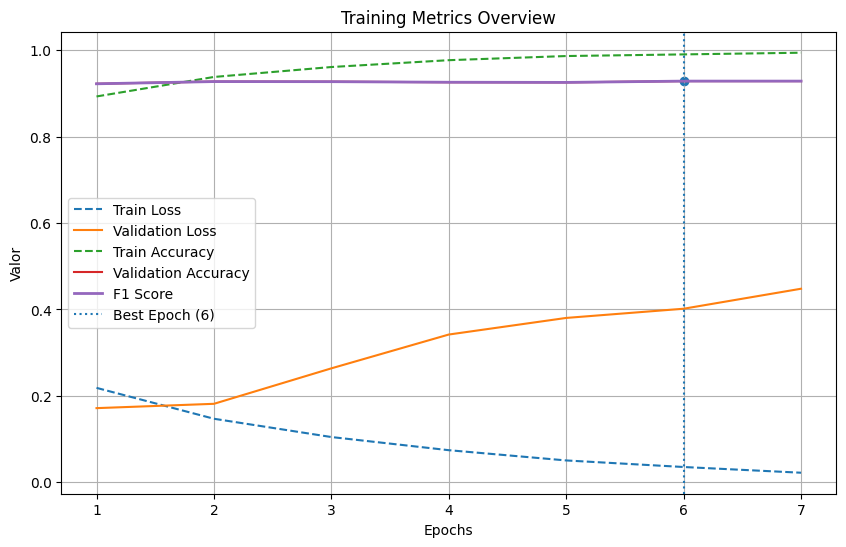

In [ ]:
epochs = np.arange(1, EPOCHS + 1)

best_epoch = np.argmax(test_f1s) + 1
best_f1 = max(test_f1s)

plt.figure(figsize=(10,6))


plt.plot(epochs, train_losses, label='Train Loss', linestyle='--')
plt.plot(epochs, test_losses, label='Validation Loss')

plt.plot(epochs, train_accuracies, label='Train Accuracy', linestyle='--')
plt.plot(epochs, test_accuracies, label='Validation Accuracy')


plt.plot(epochs, test_f1s, label='F1 Score', linewidth=2)


plt.axvline(best_epoch, linestyle=':', label=f'Best Epoch ({best_epoch})')

plt.scatter(best_epoch, best_f1)

plt.xlabel('Epochs')
plt.ylabel('Valor')
plt.title('Training Metrics Overview')
plt.legend()
plt.grid()

plt.show()

Matriz de confusión:
 [[3940  265]
 [ 336 3869]]


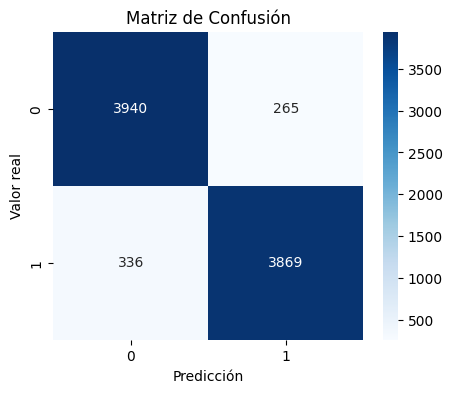

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:\n", cm)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de Confusión')
plt.show()

In [ ]:
#agregamos classification_report
from sklearn.metrics import classification_report

_, _, _, all_labels, all_preds = eval_model(
    model,
    test_data_loader,
    loss_fn,
    device,
    len(df_test)
)

print(classification_report(
    all_labels,
    all_preds,
    target_names=["No Hate", "Hate"]
    ))

/tmp/ipykernel_35404/470411350.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(): # Mixed Precision


              precision    recall  f1-score   support

     No Hate       0.92      0.94      0.93      4205
        Hate       0.94      0.92      0.93      4205

    accuracy                           0.93      8410
   macro avg       0.93      0.93      0.93      8410
weighted avg       0.93      0.93      0.93      8410



In [ ]:
#prueva manual
def predict_text(text, model, tokenizer, device, max_len=128):
    model.eval()

    encoding = tokenizer(
        text,
        truncation=True,
        padding='max_length',
        max_length=max_len,
        return_tensors='pt'
    )

    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    with torch.no_grad():
        outputs = model(input_ids, attention_mask)
        _, pred = torch.max(outputs, dim=1)

    return pred.item()

In [ ]:
#test manual
texto = "jajajaja es que es chistoso no entiendo como sales tus comentios estas bien wey pinche pendejo"
prediccion = predict_text(texto, model, tokenizer, device)

print("Texto:", texto)
print("Clase predicha:", prediccion)

In [ ]:
import torch
import os

# Guardar el modelo entrenado
model_save_path = "moderador_bert.pt"
torch.save(model.state_dict(), model_save_path)
print(f"Modelo guardado exitosamente en {model_save_path}")

# Descargar el modelo automáticamente si estás en Google Colab
try:
    from google.colab import files
    print("Descargando el modelo...")
    files.download(model_save_path)
except ImportError:
    print("No estamos en Colab, el modelo se guardó localmente.")